In [ ]:
from google.colab import files
uploaded = files.upload()

In [6]:
import cv2
img1 = cv2.imread("images (1).jpeg")
img2 = cv2.imread("images (2).jpeg")

gray1 = cv2.cvtColor(img1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(img2, cv2.COLOR_BGR2GRAY)

sift = cv2.SIFT_create()

kp1, des1 = sift.detectAndCompute(gray1, None)
kp2, des2 = sift.detectAndCompute(gray2, None)

print(f"Görüntü 1: {len(kp1)} keypoint var, descriptor : {des1.shape}")
print(f"Görüntü 2: {len(kp2)} keypoint var, descriptor : {des2.shape}")


Görüntü 1: 1337 keypoint var, descriptor : (1337, 128)
Görüntü 2: 1751 keypoint var, descriptor : (1751, 128)


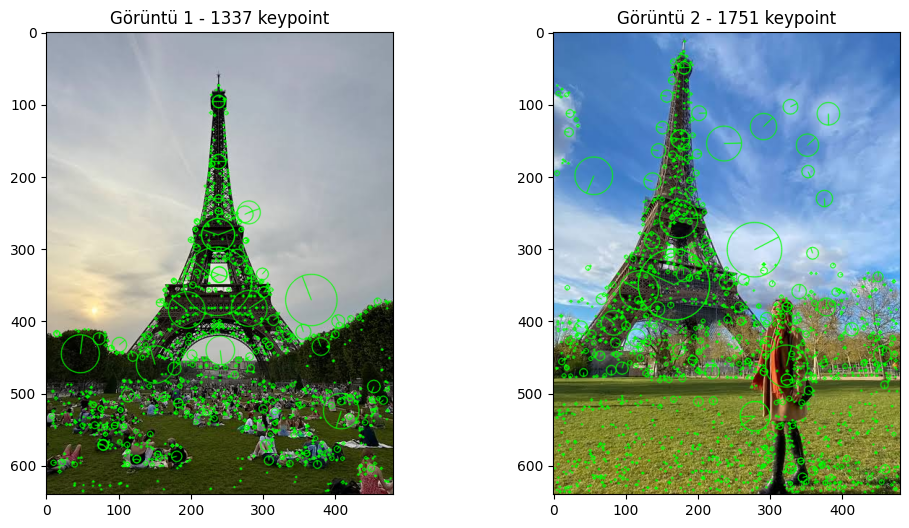

In [8]:
import matplotlib.pyplot as plt
img1_kp = cv2.drawKeypoints(img1, kp1, None, color=(0,255,0),
                             flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
img2_kp = cv2.drawKeypoints(img2, kp2, None, color=(0,255,0),
                             flags=cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)

plt.figure(figsize=(12,6))
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img1_kp, cv2.COLOR_BGR2RGB))
plt.title(f'Görüntü 1 - {len(kp1)} keypoint')

plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(img2_kp, cv2.COLOR_BGR2RGB))
plt.title(f'Görüntü 2 - {len(kp2)} keypoint')
plt.show()

In [16]:
bf = cv2.BFMatcher()

matches = bf.knnMatch(des1, des2, k=2)

good_matches = []
for m, n in matches:
    if m.distance < 0.8 * n.distance:
        good_matches.append(m)

print(f"Toplam ham eşleşme: {len(matches)}")
print(f"Ratio test sonrası iyi eşleşme: {len(good_matches)}")

Toplam ham eşleşme: 1337
Ratio test sonrası iyi eşleşme: 28


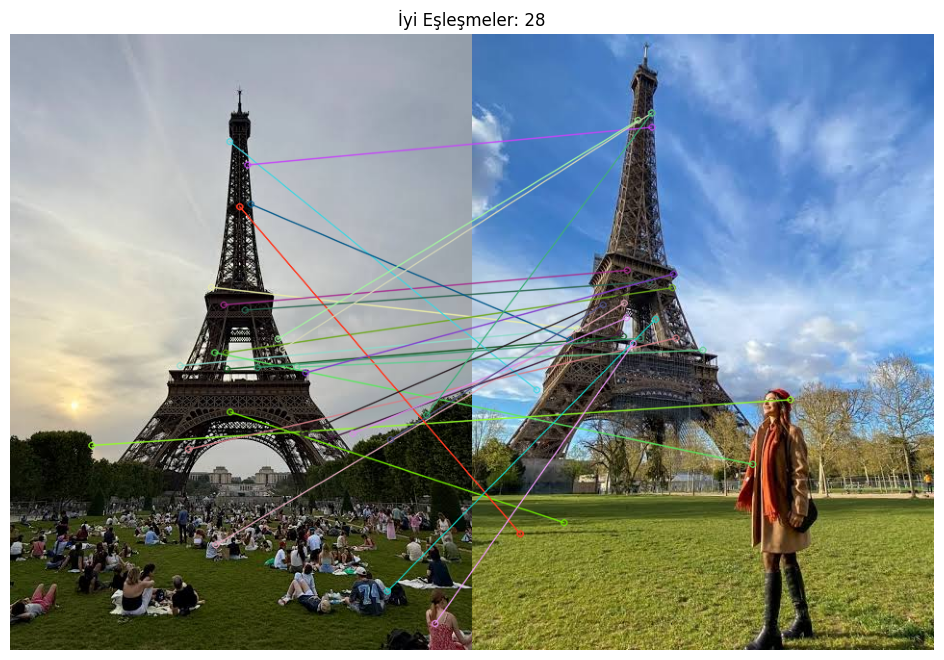

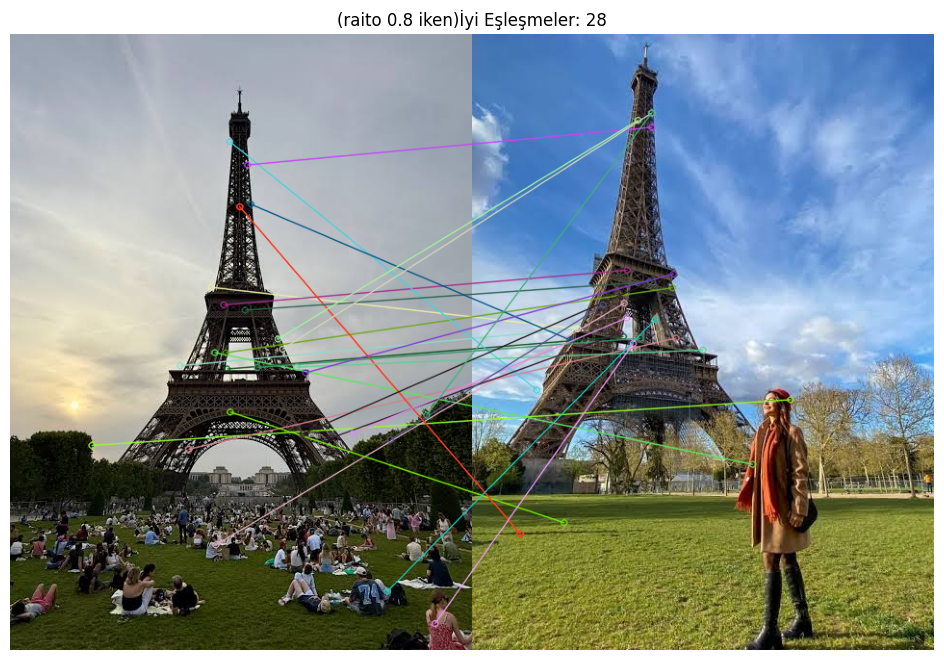

In [17]:
img_matches = cv2.drawMatches(img1, kp1, img2, kp2, good_matches, None,
                               flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)

plt.figure(figsize=(16,8))
plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))
plt.title(f'İyi Eşleşmeler: {len(good_matches)}')
plt.axis('off')
plt.show()

plt.figure(figsize=(16,8))
plt.imshow(cv2.cvtColor(img_matches, cv2.COLOR_BGR2RGB))
plt.title(f'(raito 0.8 iken)İyi Eşleşmeler: {len(good_matches)}')
plt.axis('off')
plt.savefig('sift_matches_eiffel.png', bbox_inches='tight')
plt.show()